# 04 – Waterbirds: Deep Feature Reweighting (DFR)

This notebook loads the ERM-trained ResNet-18 backbone from notebook 03, extracts 512-dim features from the frozen average-pooling layer, and retrains the last linear layer using L2 logistic regression on a group-balanced subset of the validation set (DFR). We also run an ablation over the reweighting set size.


In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, transforms
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from wilds import get_dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
torch.manual_seed(0); np.random.seed(0)


Device: cpu


In [2]:
## 1) Load Waterbirds Dataset and DataLoaders
# Use the same transforms as in notebook 03 (eval transforms for feature extraction)
dataset = get_dataset(dataset="waterbirds", download=True)

img_size = 224
train_tfms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_tfms = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_data = dataset.get_subset("train", transform=train_tfms)
val_data   = dataset.get_subset("val",   transform=eval_tfms)
test_data  = dataset.get_subset("test",  transform=eval_tfms)

place_idx = dataset.metadata_fields.index("background")  # column for background metadata

batch_size = 64
val_loader  = DataLoader(val_data,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)


In [3]:
## 2) Load Pretrained ERM Backbone
# Load the weights saved by notebook 03. We use the backbone as a frozen feature extractor.
resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
in_feats = resnet.fc.in_features
resnet.fc = nn.Linear(in_feats, 2)
erm_model = resnet.to(device)
erm_model.load_state_dict(torch.load("waterbirds_erm_resnet18.pth", map_location=device))
erm_model.eval()
print("ERM backbone loaded.")


ERM yüklendi.


/var/folders/50/l6xz49cn75g5rk4gy7bvxzy00000gn/T/ipykernel_21563/3862935328.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  erm_model.load_state_dict(torch.load("waterbi

In [4]:
## 3) Feature Extraction (512-dim from ResNet-18 avgpool)
# We hook into the model just before the fully connected layer to extract
# the 512-dimensional global average pooling features.
@torch.no_grad()
def extract_resnet_features(model, loader, place_idx):
    model.eval()
    feats, ys, gs = [], [], []
    for x, y, meta in loader:
        x = x.to(device)
        # Forward through all ResNet-18 layers up to (and including) avgpool
        h = model.conv1(x); h = model.bn1(h); h = model.relu(h); h = model.maxpool(h)
        h = model.layer1(h); h = model.layer2(h); h = model.layer3(h); h = model.layer4(h)
        h = model.avgpool(h)           # shape: [B, 512, 1, 1]
        feat = torch.flatten(h, 1)     # shape: [B, 512]
        feats.append(feat.cpu().numpy())

        y = y.numpy()
        place = meta[:, place_idx].numpy().astype(int)   # 0=land, 1=water
        g = (y.astype(int) * 2 + place).astype(int)     # group index g ∈ {0,1,2,3}
        ys.append(y); gs.append(g)

    X = np.concatenate(feats)
    y = np.concatenate(ys).astype(int)
    g = np.concatenate(gs).astype(int)
    return X, y, g

X_val,  y_val,  g_val  = extract_resnet_features(erm_model, val_loader,  place_idx)
X_test, y_test, g_test = extract_resnet_features(erm_model, test_loader, place_idx)
print("val:", X_val.shape, "| test:", X_test.shape)


val: (1199, 512) test: (5794, 512)


In [5]:
## 4) Build Group-Balanced Reweighting Set
# DFR requires a group-balanced subset of the validation features.
# We subsample to have at most `per_group` samples per group.
def subsample_by_group(X, y, g, per_group=200, seed=0):
    rng = np.random.RandomState(seed)
    idxs = []
    for gi in np.unique(g):
        cand = np.where(g == gi)[0]
        rng.shuffle(cand)
        idxs.extend(cand[:min(per_group, len(cand))])
    idxs = np.array(sorted(idxs))
    return X[idxs], y[idxs], g[idxs]

# Cap at the smallest group size or 200, whichever is smaller
per_group = min([(g_val == gi).sum() for gi in np.unique(g_val)])
per_group = min(per_group, 200)
Xv, yv, gv = subsample_by_group(X_val, y_val, g_val, per_group=per_group, seed=0)
print(f"Balanced reweighting set: {len(yv)} samples (~{per_group} per group)")


Val_clean balanced size: 532  (per_group≈ 133 )


In [6]:
## 5) DFR: Train Logistic Regression (last-layer only)
# Fit L2-regularized logistic regression on the balanced validation features.
# This replaces the ERM head with a robust linear classifier.
clf = LogisticRegression(
    penalty="l2", solver="saga", C=1.0, max_iter=2000, random_state=0
)
clf.fit(Xv, yv)
print("DFR head trained on balanced validation features.")


DFR kafa eğitildi (val_clean üzerinde).


In [7]:
## 6) Evaluate: ERM vs DFR on Test Set
def eval_lr_on(X, y, g, tag="set"):
    preds = clf.predict(X)
    mean = (preds == y).mean()
    accs = {gi: (preds[g == gi] == y[g == gi]).mean() for gi in np.unique(g)}
    worst = min(accs.values())
    print(f"[{tag}] mean={mean:.3f}, worst={worst:.3f}, groups={accs}")
    return mean, worst, accs

print("=== ERM (original classification head) ===")

@torch.no_grad()
def eval_erm_head(model, loader, place_idx, tag="ERM"):
    # Evaluate the original ERM head (model.fc) directly, without DFR
    model.eval()
    all_y, all_pred, all_g = [], [], []
    for x, y, meta in loader:
        x = x.to(device)
        pred = model(x).argmax(1).cpu().numpy()
        y = y.numpy()
        place = meta[:, place_idx].numpy().astype(int)
        g = (y.astype(int) * 2 + place).astype(int)
        all_y.append(y); all_pred.append(pred); all_g.append(g)
    y = np.concatenate(all_y); p = np.concatenate(all_pred); g = np.concatenate(all_g)
    mean = (p == y).mean()
    accs = {gi: (p[g == gi] == y[g == gi]).mean() for gi in np.unique(g)}
    worst = min(accs.values())
    print(f"[{tag}] mean={mean:.3f}, worst={worst:.3f}, groups={accs}")

eval_erm_head(erm_model, test_loader, place_idx, tag="Test (ERM)")

print("\n=== DFR (logistic regression head) ===")
eval_lr_on(X_test, y_test, g_test, tag="Test (DFR)")


=== ERM (orijinal kafa) ===
[Test (ERM)] mean=0.818, worst=0.639, groups={0: 0.9866962305986696, 1: 0.6580931263858093, 2: 0.6386292834890965, 3: 0.9626168224299065}

=== DFR (lojistik regresyon kafa) ===
[Test (DFR)] mean=0.901, worst=0.883, groups={0: 0.9006651884700665, 1: 0.9095343680709534, 2: 0.8909657320872274, 3: 0.883177570093458}


(0.9011045909561616,
 0.883177570093458,
 {0: 0.9006651884700665,
  1: 0.9095343680709534,
  2: 0.8909657320872274,
  3: 0.883177570093458})

In [8]:
## 7) Detailed Per-Group Breakdown
import numpy as np

# Descriptive names for each group (label × background combination)
names = {
    0: "g=0  landbird-on-land   (majority)",
    1: "g=1  landbird-on-water  (minority)",
    2: "g=2  waterbird-on-land  (minority)",
    3: "g=3  waterbird-on-water (majority)",
}

def print_group_stats(group_accs, g_test):
    # Print group sizes and per-group accuracy
    vals, cnts = np.unique(g_test, return_counts=True)
    print("Group counts:", {int(v): int(c) for v, c in zip(vals, cnts)})
    print("Group accuracies:")
    for gi, acc in sorted(group_accs.items()):
        print(f"  {names[gi]:40s}  acc={acc:.3f}")

# Example usage (replace dict values with your actual results):
print_group_stats(
    {0: 0.9006651884700665, 1: 0.9095343680709534, 2: 0.8909657320872274, 3: 0.883177570093458},
    g_test
)


Group counts: {0: 2255, 1: 2255, 2: 642, 3: 642}
Group accuracies:
  g=0  landbird-on-land   (match)     acc=0.901
  g=1  landbird-on-water  (mismatch)  acc=0.910
  g=2  waterbird-on-land  (mismatch)  acc=0.891
  g=3  waterbird-on-water (match)     acc=0.883


In [9]:
## 8) Ablation: Effect of Reweighting Set Size (per_group)
# Test DFR with different numbers of validation samples per group.
# A smaller reweighting set requires less labeled data but may reduce robustness.
from sklearn.linear_model import LogisticRegression

def subsample_by_group(X, y, g, per_group, seed=0):
    """Subsample at most per_group examples per group (used for ablation)."""
    rng = np.random.RandomState(seed)
    idxs = []
    for gi in np.unique(g):
        cand = np.where(g == gi)[0]
        rng.shuffle(cand)
        take = min(per_group, len(cand))
        idxs.extend(cand[:take])
    idxs = np.array(sorted(idxs))
    return X[idxs], y[idxs], g[idxs]

def train_dfr_and_eval(Xv, yv, X_test, y_test, g_test, tag="DFR"):
    clf = LogisticRegression(
        penalty="l2", solver="saga", C=1.0, max_iter=2000, random_state=0
    )
    clf.fit(Xv, yv)
    preds = clf.predict(X_test)
    mean = (preds == y_test).mean()
    accs = {gi: (preds[g_test == gi] == y_test[g_test == gi]).mean() for gi in np.unique(g_test)}
    worst = min(accs.values())
    print(f"[{tag}] mean={mean:.3f}, worst={worst:.3f}, groups={accs}")
    return mean, worst, accs

# Evaluate for per_group ∈ {50, 100, 200}
for k in [200, 100, 50]:
    Xv_k, yv_k, gv_k = subsample_by_group(X_val, y_val, g_val, per_group=k, seed=0)
    print(f"\nVal_clean per_group={k}, total size={len(yv_k)}")
    train_dfr_and_eval(Xv_k, yv_k, X_test, y_test, g_test, tag=f"DFR (per_group={k})")



Val_clean per_group=200, toplam boyut=666
[DFR (per_group=200)] mean=0.913, worst=0.868, groups={0: 0.917960088691796, 1: 0.9312638580931264, 2: 0.8769470404984424, 3: 0.867601246105919}

Val_clean per_group=100, toplam boyut=400
[DFR (per_group=100)] mean=0.903, worst=0.883, groups={0: 0.9015521064301553, 1: 0.9152993348115299, 2: 0.8847352024922118, 3: 0.883177570093458}

Val_clean per_group=50, toplam boyut=200
[DFR (per_group=50)] mean=0.894, worst=0.875, groups={0: 0.8749445676274945, 1: 0.9188470066518847, 2: 0.8878504672897196, 3: 0.883177570093458}


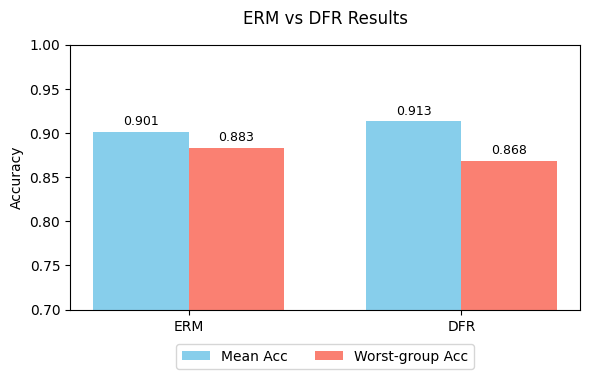

In [11]:
## 9) Visualization: ERM vs DFR Results (Bar Chart)
import matplotlib.pyplot as plt
import numpy as np

# Replace with your actual results (or read from the evaluation cells above)
methods   = ["ERM", "DFR"]
mean_acc  = [0.901, 0.913]   # mean accuracy on test set
worst_acc = [0.883, 0.868]   # worst-group accuracy on test set

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 4))

bars1 = ax.bar(x - width / 2, mean_acc,  width, label="Mean Acc",         color="skyblue")
bars2 = ax.bar(x + width / 2, worst_acc, width, label="Worst-Group Acc",  color="salmon")

# Annotate bar values
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f"{height:.3f}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

ax.set_ylim(0.7, 1.0)
ax.set_ylabel("Accuracy")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_title("ERM vs DFR — Waterbirds", pad=12, fontsize=13, fontweight="bold")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=2)

plt.tight_layout()
plt.show()


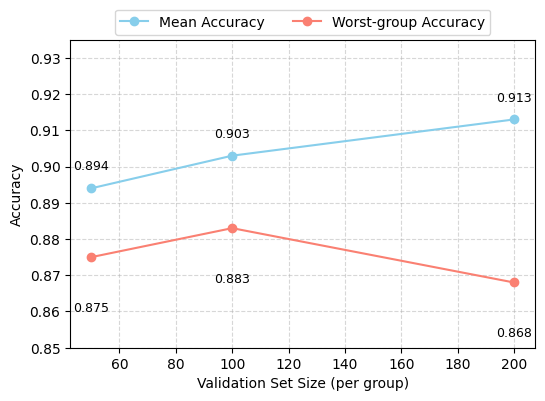

In [18]:
## 10) Visualization: Ablation — Validation Set Size vs Accuracy
import matplotlib.pyplot as plt

# Results for per_group ∈ {50, 100, 200}
val_sizes = [50, 100, 200]
mean_acc  = [0.894, 0.903, 0.913]
worst_acc = [0.875, 0.883, 0.868]

plt.figure(figsize=(6, 4))
plt.plot(val_sizes, mean_acc,  marker="o", label="Mean Accuracy",         color="skyblue")
plt.plot(val_sizes, worst_acc, marker="o", label="Worst-Group Accuracy",  color="salmon")

# Annotate each data point
for x, y in zip(val_sizes, mean_acc):
    plt.text(x, y + 0.005, f"{y:.3f}", ha="center", fontsize=9)
for x, y in zip(val_sizes, worst_acc):
    plt.text(x, y - 0.015, f"{y:.3f}", ha="center", fontsize=9)

plt.xlabel("Validation Set Size (per group)")
plt.ylabel("Accuracy")
plt.ylim(0.85, 0.935)  # expand upper bound so top labels are not clipped
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2)
plt.grid(True, linestyle="--", alpha=0.5)
plt.title("DFR Ablation: Reweighting Set Size", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()
